In [105]:
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from Protein_Sequence_Based_Prediction_of_Folding_Kinetics import(
    fetch_dataset,
    validate_dataset
)

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman"]


In [79]:
# -------------------------------
# Import data
# -------------------------------
data = fetch_dataset()
report = validate_dataset(data)

# Ensure the one-to-one relationship established for measurement_id
assert data["measurement_id"].is_unique
assert len(data) == data["measurement_id"].nunique()

report

C:\Users\isasu\OneDrive\Projects\Protein-Sequence-Based-Prediction-of-Folding-Kinetics\src\Protein_Sequence_Based_Prediction_of_Folding_Kinetics\load.py:100: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql_query(query, connection)


{'rows': 1381,
 'unique_measurements': 1381,
 'duplicate_measurement_ids': 0,
 'unique_proteins': 61,
 'unique_mutations': 1338,
 'missing_target': 257,
 'missing_reference_context': 399,
 'missing_mutation_context': 399}

In [129]:
# Explore data columns with most missing data
data.isna().mean().sort_values(ascending=False).head(15)

beta_t               0.960174
additives            0.755250
ec_number            0.712527
ddgkin_h2o           0.445329
dg_kin_h2o           0.380159
dln_ku_h2o           0.292542
reference_context    0.288921
mutation_context     0.288921
dln_kf_h2o           0.244750
ln_ku_h2o            0.230992
mf                   0.221579
ln_kf_h2o            0.186097
mu                   0.149891
reversibility        0.108617
cath                 0.083997
dtype: float64

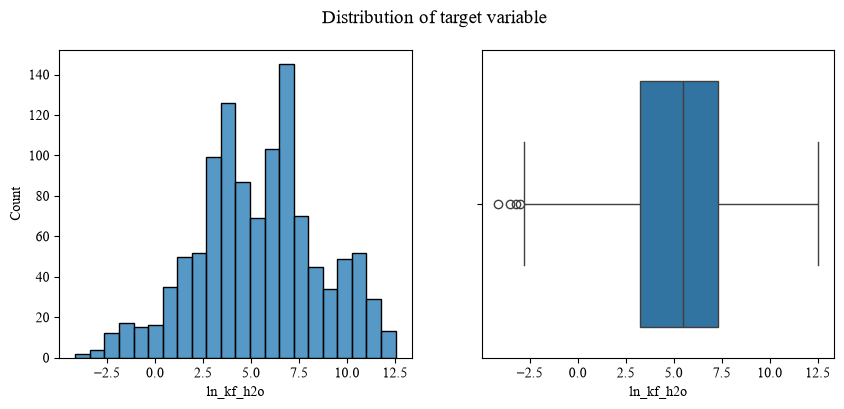

In [80]:
# Explore distribution of target variable
fig, ax = plt.subplots(1, 2, figsize = (10, 4))

sns.histplot(data = data, x = 'ln_kf_h2o', ax = ax[0])
sns.boxplot(data = data, x = 'ln_kf_h2o', ax = ax[1])
fig.suptitle('Distribution of target variable', fontsize = 14)
plt.show()

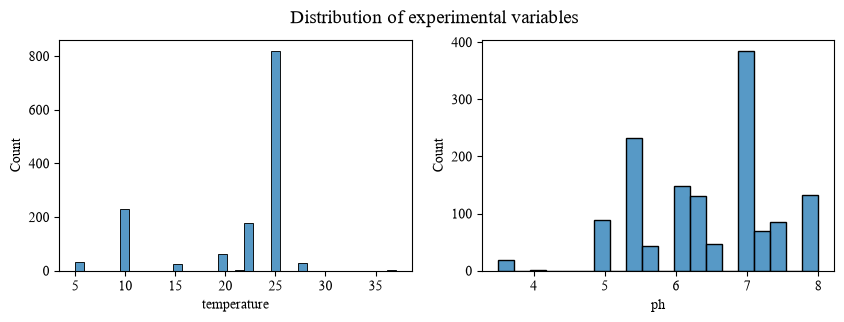

In [100]:
# Explore the applied methodologies
fig, ax = plt.subplots(1, 2, figsize = (10, 3))

sns.histplot(data = data, x = 'temperature', ax = ax[0])
sns.histplot(data = data, x = 'ph', ax = ax[1])
fig.suptitle('Distribution of experimental variables', fontsize = 14)
plt.show()

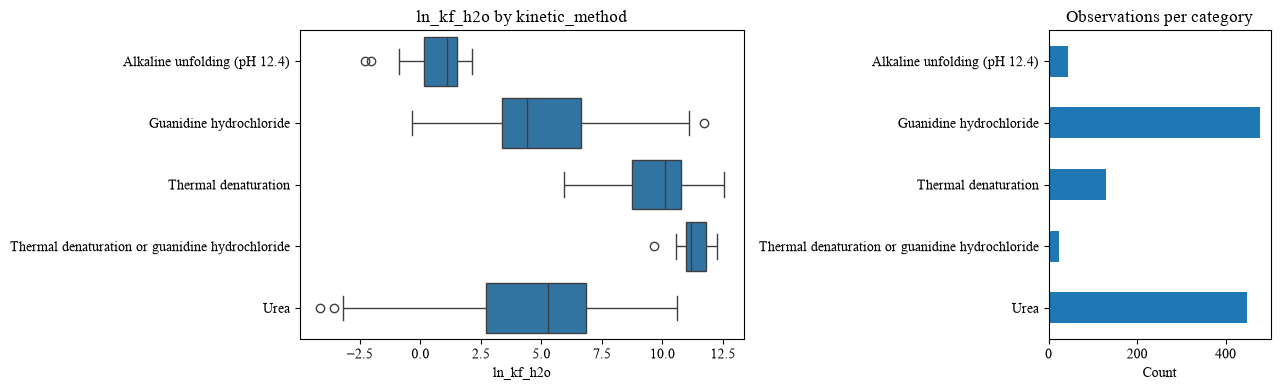

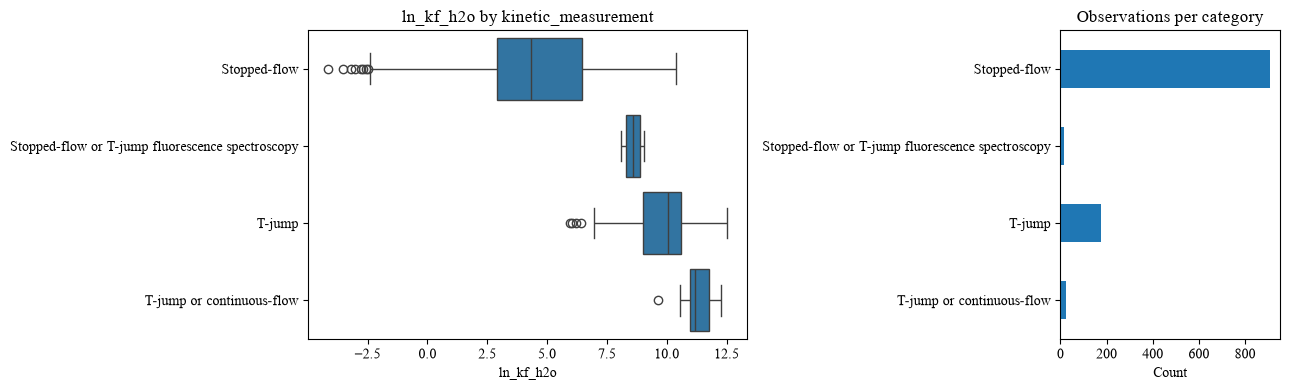

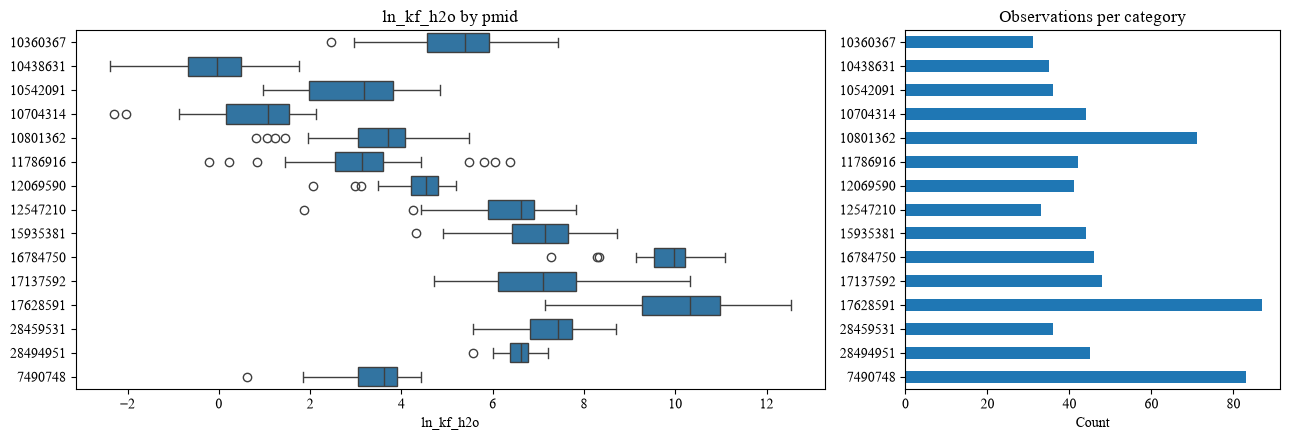

In [122]:
def plot_category_effect(data, category, target='ln_kf_h2o', min_count=10, top_n=15):
    plot_df = data[[category, target]].dropna().copy()

    # Keep sufficiently represented categories and limit very long plots.
    counts = plot_df[category].value_counts()
    categories = counts[counts >= min_count].head(top_n).index
    plot_df = plot_df[plot_df[category].isin(categories)]

    if plot_df.empty:
        print(f"No categories in {category!r} meet the minimum count.")
        return

    order = (
        plot_df.groupby(category)[target]
        .median()
        .sort_index()
        .index
    )

    fig, axes = plt.subplots(
        1, 2, figsize=(13, max(4, len(order) * 0.3)),
        gridspec_kw={"width_ratios": [2, 1]}
    )

    sns.boxplot(data=plot_df, x=target, y=category, order=order, ax=axes[0])
    axes[0].set_title(f"{target} by {category}")
    axes[0].set_ylabel("")

    count_order = plot_df[category].value_counts().sort_index(ascending = False)
    count_order.plot.barh(ax=axes[1])
    axes[1].set_title("Observations per category")
    axes[1].set_xlabel("Count")
    axes[1].set_ylabel("")

    fig.tight_layout()
    plt.show()


plot_category_effect(data, "kinetic_method")
plot_category_effect(data, "kinetic_measurement")
plot_category_effect(
    data,
    category="pmid",
    min_count=10,
    top_n=15,
)

In [104]:
# Explore proteins and mutations pr. experimental category
data_by_experiment = data.groupby(['kinetic_method', 'kinetic_measurement']).agg(
    unique_proteins = ('protein_id', 'nunique'),
    unique_mutations = ('mutation_id', 'nunique')
)
print('\n', data_by_experiment)


                                                                                                   unique_proteins  unique_mutations
kinetic_method                                  kinetic_measurement                                                                
Alkaline unfolding (pH 12.4)                    Stopped-flow                                                    1                44
Guanidine hydrochloride                         Manual mixing                                                   1                 1
                                                Stopped-flow                                                   26               577
                                                Stopped-flow or T-jump fluorescence spectroscopy                1                15
                                                T-jump                                                          1                46
Thermal denaturation                            T-jump                    

In [ ]:
# For numeric variables: Explore coverage, spread, and association with target
for col in ["temperature", "ph"]:
    subset = data[[col, 'ln_kf_h2o']].dropna()

    print(f"\n{col}")
    print(f"Observations: {len(subset)}")
    print(f"Unique values: {subset[col].nunique()}")
    print(f"Spearman correlation: "
          f"{subset[col].corr(subset['ln_kf_h2o'], method='spearman'):.3f}")

# For categorical variables: Explore group-level variation
for col in ["kinetic_method", "kinetic_measurement", "pmid"]:
    summary = (
        data.dropna(subset=[col, 'ln_kf_h2o'])
        .groupby(col)['ln_kf_h2o']
        .agg(["count", "median", "mean", "std"])
        .sort_values("count", ascending=False)
    )

    print(f"\n{col}")
    print(summary.head(15).round(3))


temperature
Observations: 1124
Unique values: 9
Spearman correlation: -0.302

ph
Observations: 1124
Unique values: 17
Spearman correlation: -0.151

kinetic_method
                                                 count  median    mean    std
kinetic_method                                                               
Guanidine hydrochloride                            478   4.395   5.095  2.332
Urea                                               449   5.280   4.573  2.980
Thermal denaturation                               130  10.110   9.727  1.460
Alkaline unfolding (pH 12.4)                        44   1.080   0.726  1.055
Thermal denaturation or guanidine hydrochloride     23  11.160  11.260  0.587

kinetic_measurement
                                                  count  median    mean    std
kinetic_measurement                                                           
Stopped-flow                                        906   4.315   4.328  2.503
T-jump                          

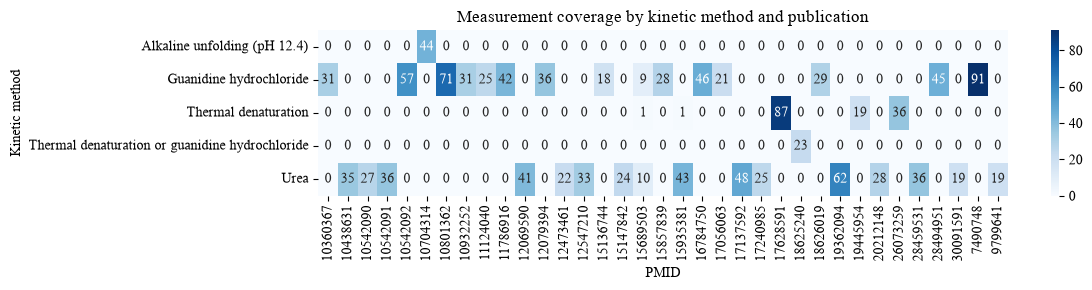

In [137]:
coverage = pd.crosstab(data["kinetic_method"], data["pmid"])

# Keep the most represented methods and publications for readability.
top_methods = data["kinetic_method"].value_counts().head(10).index
top_pmids = data["pmid"].value_counts().head(35).index

coverage = coverage.loc[
    coverage.index.intersection(top_methods),
    coverage.columns.intersection(top_pmids),
]

plt.figure(figsize=(12, 3))
sns.heatmap(coverage, annot=True, fmt="d", cmap="Blues")
plt.title("Measurement coverage by kinetic method and publication")
plt.xlabel("PMID")
plt.ylabel("Kinetic method")
plt.tight_layout()
plt.show()

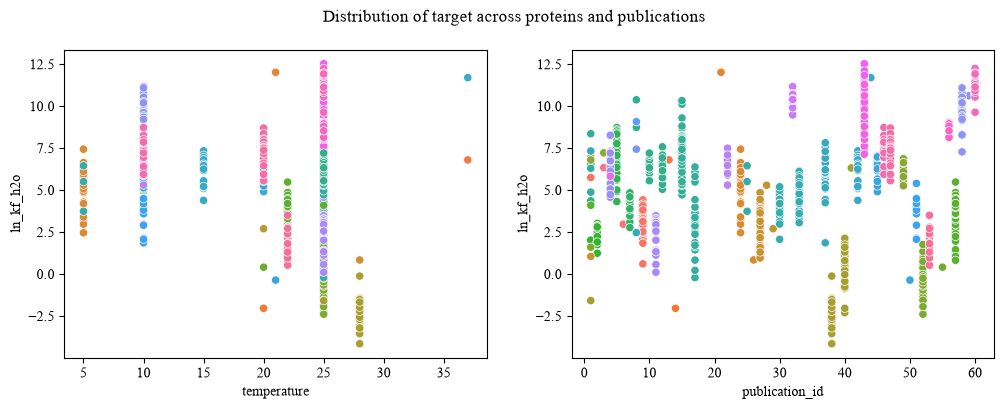

In [141]:
fig, ax = plt.subplots(1, 2, figsize = (12, 4))
sns.scatterplot(data = data, y = 'ln_kf_h2o', x = 'temperature', hue = 'protein_name', ax = ax[0], legend = False)
sns.scatterplot(data = data, y = 'ln_kf_h2o', x = 'publication_id', hue = 'protein_name', ax = ax[1], legend = False)
fig.suptitle('Distribution of target across proteins and publications')
plt.show()